
# FlashPoint square detector: edge + central-array position-resolution scan

This notebook follows the reconstruction convention used in `FlashPoint_clean_posreco.ipynb`, but is designed to process **all edge + center-array productions sequentially** without keeping every configuration in memory at once.

Main reconstruction used for the scan:

$$
A+t_1+t_2+t_3 \;\longrightarrow\; \text{ExtraTrees}(x,y)
$$

with event-by-event timing aligned to the earliest detected photon and an optional Gaussian single-photon timing jitter.

The inclusive position resolution is

$$
\sigma_{xy}=
\sqrt{\frac{\sigma_x^2+\sigma_y^2}{2}},
\qquad
\sigma_{xy}^{\rm rel}=100\,\frac{\sigma_{xy}}{L}.
$$

The notebook also records central-region and outer-region performance, \(R_{68}\), \(R_{90}\), local resolution maps, total channel count, and edge/center sampling pitch.


In [1]:

# 0. Imports + global configuration
from pathlib import Path
import gc
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from IPython.display import display
from sklearn.ensemble import ExtraTreesRegressor

SEED = 42

# Detector
LENGTH = 1000.0   # mm
HALF = LENGTH / 2

# Same timing convention as the previous edge notebook
APPLY_TIMING_SMEARING = True
TIMING_SIGMA_PS = 300

# ExtraTrees settings: same basic choice as the previous notebook
TRAIN_FRAC = 0.70
ML_TRAIN_MAX = 100_000
N_ESTIMATORS = 300
MIN_SAMPLES_LEAF = 2
MAX_FEATURES = 0.8
MODEL_N_JOBS = -1

# Local map
MAP_GRID_N = 40
MIN_CELL = 10

# Diagnostic regions
CENTER_HALF = 250.0   # |x|,|y| < 250 mm
EDGE_BAND = 150.0     # outer 150 mm strip

# Input produced by submit_production.sh
RUN = Path("/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter")

OUT = RUN / "edge_center_position_study"
OUT.mkdir(parents=True, exist_ok=True)
MAP_OUT = OUT / "maps"
MAP_OUT.mkdir(parents=True, exist_ok=True)

# Optional quick debugging
MAX_FILES = None      # e.g. 2 for a quick check
SAVE_PREDICTIONS = False
VALIDATE_HIT_COUNTS = True

print("RUN =", RUN)
print("OUT =", OUT)


RUN = /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter
OUT = /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/edge_center_position_study


In [2]:

# 1. All submitted configurations
SETUPS = [
    # ~100 channels
    (20, 4),
    (15, 6),
    ( 8, 8),

    # intermediate
    (18, 6),
    (24, 4),
    (20, 6),
    ( 9, 9),
    (22, 6),
    (15, 8),

    # higher channel counts
    (24, 6),
    (18, 8),
    (10,10),
    (20, 8),
    (24, 8),
    (15,10),
    (11,11),
]

# Optional old Edge24 reference. Turn on only if the corresponding directory exists.
ADD_EDGE24_BASELINE = False
if ADD_EDGE24_BASELINE:
    SETUPS = [(24, 0)] + SETUPS

def setup_info(nedge, narray):
    perimeter = 4 + 4*nedge
    center = narray*narray
    total = perimeter + center

    # Edge-contact span follows the previous square notebook.
    edge_contact = HALF - 2.1460690809
    edge_pitch = 2*edge_contact/(nedge+1)
    center_pitch = LENGTH/(narray+1) if narray > 0 else np.nan

    return dict(
        edge=nedge,
        array=narray,
        perimeter_channels=perimeter,
        center_channels=center,
        total_channels=total,
        edge_pitch_mm=edge_pitch,
        center_pitch_mm=center_pitch,
        pitch_ratio=center_pitch/edge_pitch if narray > 0 else np.nan,
    )

setup_table = pd.DataFrame([setup_info(*s) for s in SETUPS])
display(setup_table.round(2))


,edge,array,perimeter_channels,center_channels,total_channels,edge_pitch_mm,center_pitch_mm,pitch_ratio
0,20,4,84,16,100,47.41,200.00,4.22
1,15,6,64,36,100,62.23,142.86,2.30
2,8,8,36,64,100,110.63,111.11,1.00
3,18,6,76,36,112,52.41,142.86,2.73
4,24,4,100,16,116,39.83,200.00,5.02
5,20,6,84,36,120,47.41,142.86,3.01
6,9,9,40,81,121,99.57,100.00,1.00
7,22,6,92,36,128,43.29,142.86,3.30
8,15,8,64,64,128,62.23,111.11,1.79
9,24,6,100,36,136,39.83,142.86,3.59


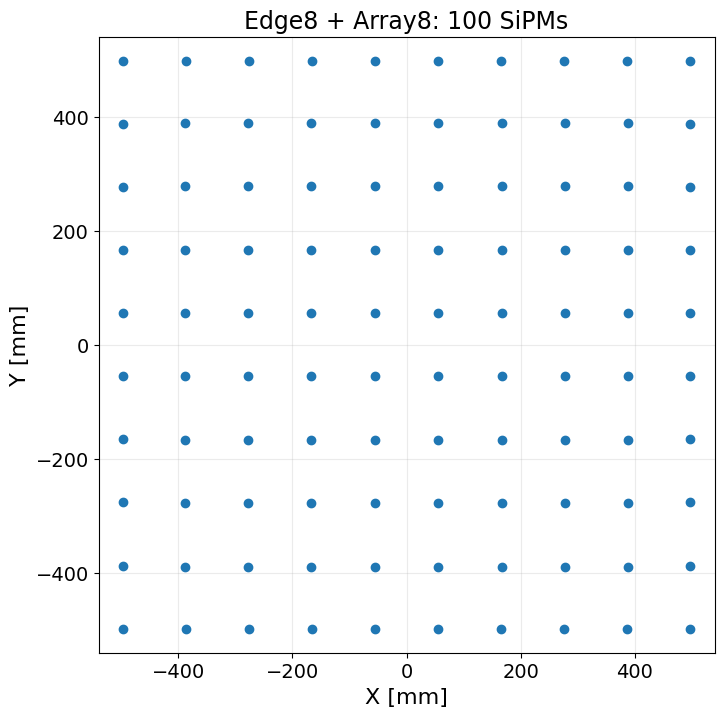

In [3]:

# 2. SiPM positions: same perimeter convention + new +Z center array

def get_pos(nedge, narray):
    edge = HALF - 2.1460690809
    pos = [
        [ edge, edge],
        [-edge, edge],
        [-edge,-edge],
        [ edge,-edge],
    ]

    if nedge:
        u = np.linspace(-edge, edge, nedge+2)[1:-1]
        pos += [[ x, edge] for x in u]       # +Y
        pos += [[edge,-y] for y in u]        # +X
        pos += [[-x,-edge] for x in u]       # -Y
        pos += [[-edge,y] for y in u]        # -X

    if narray:
        dx = LENGTH/(narray+1)
        dy = LENGTH/(narray+1)
        for iy in range(narray):
            y = -HALF + (iy+1)*dy
            for ix in range(narray):
                x = -HALF + (ix+1)*dx
                pos.append([x,y])

    return np.asarray(pos, float)

# Geometry sanity check for the matched 100-channel case
NEDGE_SHOW, NARRAY_SHOW = 8, 8
POS = get_pos(NEDGE_SHOW, NARRAY_SHOW)
expected = 4 + 4*NEDGE_SHOW + NARRAY_SHOW**2
assert len(POS) == expected

fig, ax = plt.subplots(figsize=(9,8))
ax.scatter(POS[:,0], POS[:,1])
ax.set(
    xlabel="X [mm]", ylabel="Y [mm]",
    title=f"Edge{NEDGE_SHOW} + Array{NARRAY_SHOW}: {expected} SiPMs",
    xlim=(-HALF-40, HALF+40), ylim=(-HALF-40, HALF+40),
    aspect="equal",
)
ax.tick_params(labelsize=14)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)
ax.grid(alpha=.25)
plt.show()



## 3. ROOT loading and timing extraction

For each setup the notebook:

1. reads one ROOT job file at a time;
2. checks the expected `n_detected_sipm<i>` branches;
3. maps detected photons in the `hits` tree to event and SiPM;
4. optionally applies the same Gaussian timing jitter used in the edge notebook;
5. recalculates the event-wide earliest photon \(t_0\);
6. builds \(t_1,t_2,t_3\) for every SiPM;
7. concatenates only the arrays needed for the reconstruction.

Each configuration is reconstructed and then released from memory before moving to the next one.


In [4]:

# 3a. ROOT helpers
TIME_NAMES = ["t_plot_ns", "t_ns", "time_ns", "arrival_time_ns", "global_time_ns"]
X_NAMES = ["source_x_mm", "x_source_mm", "source_x", "x_true_mm"]
Y_NAMES = ["source_y_mm", "y_source_mm", "source_y", "y_true_mm"]

def integer_ids(values, label):
    values = np.asarray(values)
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f"{label} must contain finite integer IDs")
    return values.astype(np.int64)

def first_existing(keys, names):
    keys = set(keys)
    return next((x for x in names if x in keys), None)

def read_hits(f, local_event_ids, nsipm):
    if "hits" not in f:
        raise KeyError("Missing 'hits' tree")

    tree = f["hits"]
    time_name = first_existing(tree.keys(), TIME_NAMES)
    if time_name is None:
        raise KeyError(f"No timing branch found; tried {TIME_NAMES}")

    h = tree.arrays(["event", "sipm", time_name], library="np")
    hev = integer_ids(h["event"], "hits.event")
    sipm = integer_ids(h["sipm"], "hits.sipm")
    tm = np.asarray(h[time_name], dtype=np.float64)

    row = pd.Index(local_event_ids).get_indexer(hev)

    if (row < 0).any():
        raise ValueError("Some hit-event IDs do not map to the events tree")
    if ((sipm < 0) | (sipm >= nsipm)).any():
        raise ValueError("Out-of-range SiPM ID in hits tree")
    if not np.isfinite(tm).all():
        raise ValueError("Non-finite hit time")

    return row, sipm, tm

def extract_t123(row, sipm, tm, nevents, nsipm, sigma_ps, rng):
    tm = tm.copy()

    if sigma_ps > 0:
        tm += rng.normal(0.0, sigma_ps/1000.0, len(tm))

    # Earliest detected photon in each event
    t0 = np.full(nevents, np.inf)
    np.minimum.at(t0, row, tm)
    dt = tm - t0[row]

    # Sort detected photons within each (event, SiPM)
    group = row*nsipm + sipm
    order = np.lexsort((tm, group))
    gs = group[order]

    starts = (
        np.flatnonzero(np.r_[True, gs[1:] != gs[:-1]])
        if len(gs) else np.empty(0, dtype=int)
    )
    ends = np.r_[starts[1:], len(gs)]

    out = []
    for k in range(3):
        target = np.full((nevents, nsipm), np.nan, dtype=np.float32)
        valid = starts + k < ends
        take = starts[valid] + k
        target.ravel()[gs[take]] = dt[order[take]]
        out.append(target)

    return tuple(out)

def setup_directory(nedge, narray):
    return RUN / f"output_edge{nedge}_array{narray}_{int(LENGTH)}"

def load_setup(nedge, narray):
    info = setup_info(nedge, narray)
    nsipm = info["total_channels"]

    indir = setup_directory(nedge, narray)
    files = sorted(indir.glob("*.root"))
    if MAX_FILES is not None:
        files = files[:MAX_FILES]

    if not files:
        raise FileNotFoundError(f"No ROOT files found in {indir}")

    truth_blocks = []
    amp_blocks = []
    t1_blocks, t2_blocks, t3_blocks = [], [], []

    rng_smear = np.random.default_rng(SEED + 100)

    for job, fname in enumerate(files):
        with uproot.open(fname) as f:
            if "events" not in f:
                raise KeyError(f"{fname}: missing events tree")

            et = f["events"]
            keys = et.keys()

            xname = first_existing(keys, X_NAMES)
            yname = first_existing(keys, Y_NAMES)
            if xname is None or yname is None:
                raise KeyError(f"{fname}: truth X/Y branches not found")

            amp_names = [f"n_detected_sipm{i}" for i in range(nsipm)]
            missing = [x for x in amp_names if x not in keys]
            if missing:
                raise KeyError(
                    f"{fname.name}: expected {nsipm} SiPM amplitude branches; "
                    f"first missing branch is {missing[0]}"
                )

            read_names = [xname, yname] + amp_names
            if "event" in keys:
                read_names = ["event"] + read_names

            e = et.arrays(read_names, library="np")
            n = et.num_entries

            local = integer_ids(
                e["event"] if "event" in e else np.arange(n),
                "events.event"
            )

            truth = np.column_stack([e[xname], e[yname]]).astype(np.float32)
            A = np.column_stack([e[x] for x in amp_names])

            if not np.isfinite(A).all() or (A < 0).any():
                raise ValueError(f"{fname.name}: invalid amplitude values")

            row, sipm, tm = read_hits(f, local, nsipm)

            if VALIDATE_HIT_COUNTS:
                hit_count = np.bincount(
                    row*nsipm + sipm,
                    minlength=n*nsipm
                ).reshape(n, nsipm)

                if not np.array_equal(A, hit_count):
                    raise ValueError(
                        f"{fname.name}: hits tree counts disagree with "
                        "n_detected_sipm<i> branches"
                    )

            t1, t2, t3 = extract_t123(
                row, sipm, tm, n, nsipm,
                TIMING_SIGMA_PS if APPLY_TIMING_SMEARING else 0,
                rng_smear
            )

            truth_blocks.append(truth)
            amp_blocks.append(A)
            t1_blocks.append(t1)
            t2_blocks.append(t2)
            t3_blocks.append(t3)

        print(
            f"  {job:2d}  {fname.name:48s}  "
            f"events={n:6d}"
        )

    truth = np.concatenate(truth_blocks).astype(np.float32, copy=False)
    A = np.concatenate(amp_blocks).astype(np.float32, copy=False)
    T1 = np.concatenate(t1_blocks)
    T2 = np.concatenate(t2_blocks)
    T3 = np.concatenate(t3_blocks)

    ntot = A.sum(axis=1)
    good = (
        np.isfinite(truth).all(axis=1)
        & (ntot > 0)
        & (np.abs(truth) <= HALF).all(axis=1)
    )

    truth = truth[good]
    A = A[good]
    T1 = T1[good]
    T2 = T2[good]
    T3 = T3[good]
    ntot = ntot[good]

    print(
        f"  usable={len(truth):,}, "
        f"mean detected photons/event={ntot.mean():.2f}"
    )

    return truth, A, T1, T2, T3


In [5]:

# 4. Metrics + local position-resolution map

def sigma_xy_from_residual(d):
    if len(d) == 0:
        return np.nan
    sx = np.std(d[:,0])
    sy = np.std(d[:,1])
    return np.sqrt((sx*sx + sy*sy)/2)

def resolution_metrics(truth, pred):
    valid = np.isfinite(pred).all(axis=1) & np.isfinite(truth).all(axis=1)
    t = truth[valid]
    p = pred[valid]
    d = p - t

    dx, dy = d[:,0], d[:,1]
    r = np.hypot(dx, dy)

    sx, sy = np.std(dx), np.std(dy)
    sxy = np.sqrt((sx*sx + sy*sy)/2)

    center = (np.abs(t[:,0]) < CENTER_HALF) & (np.abs(t[:,1]) < CENTER_HALF)
    outer = np.maximum(np.abs(t[:,0]), np.abs(t[:,1])) > (HALF - EDGE_BAND)

    return dict(
        N=len(t),
        coverage=valid.mean(),
        bias_x_mm=np.mean(dx),
        bias_y_mm=np.mean(dy),
        sigma_x_mm=sx,
        sigma_y_mm=sy,
        sigma_xy_mm=sxy,
        relative_sigma_xy_pct=100*sxy/LENGTH,
        RMSE_xy_mm=np.sqrt(np.mean(d*d)),
        R68_mm=np.quantile(r, .68),
        R90_mm=np.quantile(r, .90),
        sigma_xy_center_mm=sigma_xy_from_residual(d[center]),
        sigma_xy_outer_mm=sigma_xy_from_residual(d[outer]),
    )

def local_sigma_map(truth, pred, grid_n=MAP_GRID_N, min_cell=MIN_CELL):
    valid = np.isfinite(pred).all(axis=1) & np.isfinite(truth).all(axis=1)
    t = truth[valid]
    d = pred[valid] - t

    edges = np.linspace(-HALF, HALF, grid_n+1)
    ix = np.clip(np.searchsorted(edges, t[:,0], side="right") - 1, 0, grid_n-1)
    iy = np.clip(np.searchsorted(edges, t[:,1], side="right") - 1, 0, grid_n-1)
    gid = iy*grid_n + ix
    ncell = grid_n*grid_n

    count = np.bincount(gid, minlength=ncell)

    sums = np.column_stack([
        np.bincount(gid, weights=d[:,j], minlength=ncell)
        for j in range(2)
    ])
    sums2 = np.column_stack([
        np.bincount(gid, weights=d[:,j]**2, minlength=ncell)
        for j in range(2)
    ])

    mean = np.divide(
        sums, count[:,None],
        out=np.zeros_like(sums),
        where=count[:,None] > 0
    )
    second = np.divide(
        sums2, count[:,None],
        out=np.zeros_like(sums2),
        where=count[:,None] > 0
    )

    var = np.maximum(second - mean**2, 0)
    sxy = np.sqrt(var.mean(axis=1))
    sxy[count < min_cell] = np.nan

    return sxy.reshape(grid_n, grid_n), count.reshape(grid_n, grid_n)

def save_local_map(nedge, narray, sxy):
    fig, ax = plt.subplots(figsize=(9,8))
    im = ax.imshow(
        sxy, origin="lower",
        extent=(-HALF, HALF, -HALF, HALF),
        aspect="equal", vmin=0
    )

    centers = np.linspace(
        -HALF + LENGTH/(2*MAP_GRID_N),
         HALF - LENGTH/(2*MAP_GRID_N),
         MAP_GRID_N
    )
    X, Y = np.meshgrid(centers, centers)

    finite = sxy[np.isfinite(sxy)]
    if len(finite) and finite.min() < 10 < finite.max():
        cs = ax.contour(X, Y, sxy, levels=[10], linewidths=2)
        ax.clabel(cs, fmt="10 mm", fontsize=12)

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.set(
        xlabel="Truth X [mm]",
        ylabel="Truth Y [mm]",
        title=f"Edge{nedge} + Array{narray}"
    )
    ax.tick_params(labelsize=14)
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)
    ax.title.set_size(17)

    plt.tight_layout()
    fname = MAP_OUT / f"resolution_map_edge{nedge}_array{narray}.png"
    plt.savefig(fname, dpi=180, bbox_inches="tight")
    plt.close(fig)

    return fname


In [6]:

# 5. ExtraTrees reconstruction: A + t1 + t2 + t3

def training_medians(X):
    med = np.zeros(X.shape[1], dtype=np.float32)
    finite_columns = np.isfinite(X).any(axis=0)
    med[finite_columns] = np.nanmedian(X[:,finite_columns], axis=0)
    return med

def build_features(A, T1, T2, T3, indices):
    ntot = A.sum(axis=1)
    F = A / np.where(ntot[:,None] > 0, ntot[:,None], np.nan)
    logN = np.log1p(ntot)[:,None]

    return np.hstack([
        F[indices],
        logN[indices],
        T1[indices],
        T2[indices],
        T3[indices],
    ]).astype(np.float32, copy=False)

def reconstruct_setup(nedge, narray):
    info = setup_info(nedge, narray)
    nsipm = info["total_channels"]

    print("\n" + "="*78)
    print(
        f"Edge{nedge} + Array{narray} | "
        f"perimeter={info['perimeter_channels']}, "
        f"center={info['center_channels']}, total={nsipm}"
    )
    print("Input:", setup_directory(nedge, narray))

    truth, A, T1, T2, T3 = load_setup(nedge, narray)

    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(truth))
    ntr = int(TRAIN_FRAC*len(idx))
    itr, ite = idx[:ntr], idx[ntr:]

    itr_ml = (
        itr if len(itr) <= ML_TRAIN_MAX
        else rng.choice(itr, ML_TRAIN_MAX, replace=False)
    )

    Xtr = build_features(A, T1, T2, T3, itr_ml)
    med = training_medians(Xtr)
    Xtr = np.where(np.isfinite(Xtr), Xtr, med)

    model = ExtraTreesRegressor(
        n_estimators=N_ESTIMATORS,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        max_features=MAX_FEATURES,
        n_jobs=MODEL_N_JOBS,
        random_state=SEED,
    )
    model.fit(Xtr, truth[itr_ml])
    del Xtr

    # Predict in chunks to keep peak RAM lower.
    chunk = 5000
    pred = np.empty((len(ite), 2), dtype=np.float32)

    for s in range(0, len(ite), chunk):
        ids = ite[s:s+chunk]
        Xq = build_features(A, T1, T2, T3, ids)
        Xq = np.where(np.isfinite(Xq), Xq, med)
        pred[s:s+len(ids)] = model.predict(Xq)
        del Xq

    test_truth = truth[ite]
    met = resolution_metrics(test_truth, pred)
    sxy_map, count_map = local_sigma_map(test_truth, pred)

    map_file = save_local_map(nedge, narray, sxy_map)

    if SAVE_PREDICTIONS:
        np.savez_compressed(
            OUT / f"pred_edge{nedge}_array{narray}.npz",
            truth=test_truth,
            pred=pred,
        )

    result = {
        **info,
        **met,
        "events_total": len(truth),
        "events_train": len(itr),
        "events_train_ml": len(itr_ml),
        "events_test": len(ite),
        "mean_detected_photons": float(A.sum(axis=1).mean()),
        "map_file": str(map_file),
    }

    print(
        f"  sigma_xy = {met['sigma_xy_mm']:.2f} mm "
        f"({met['relative_sigma_xy_pct']:.3f}%)"
    )
    print(
        f"  center   = {met['sigma_xy_center_mm']:.2f} mm, "
        f"outer = {met['sigma_xy_outer_mm']:.2f} mm, "
        f"R68 = {met['R68_mm']:.2f} mm"
    )

    # Keep only small map/results objects after each setup.
    del model, truth, A, T1, T2, T3, pred, test_truth, count_map
    gc.collect()

    return result, sxy_map



## 6. Run the full scan

This cell processes every submitted configuration sequentially.

If one production is missing, the notebook records the error and continues with the remaining samples.


In [7]:

# 6. Process all configurations
results = []
maps = {}
failed = []

for nedge, narray in SETUPS:
    try:
        result, sxy_map = reconstruct_setup(nedge, narray)
        results.append(result)
        maps[(nedge, narray)] = sxy_map

        # Save incremental summary so a long scan is not lost.
        pd.DataFrame(results).to_csv(
            OUT / "edge_center_position_summary_partial.csv",
            index=False
        )

    except Exception as exc:
        failed.append((nedge, narray, repr(exc)))
        warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")

summary = pd.DataFrame(results)

if len(summary):
    summary = summary.sort_values(
        ["sigma_xy_mm", "total_channels"]
    ).reset_index(drop=True)

    summary.to_csv(
        OUT / "edge_center_position_summary.csv",
        index=False
    )

display(summary.round(3))

if failed:
    print("\nFailed / missing setups:")
    display(pd.DataFrame(failed, columns=["edge","array","error"]))



Edge20 + Array4 | perimeter=84, center=16, total=100
Input: /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge20_array4_1000


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_64162/711316369.py:20: UserWarning: Edge20 Array4 failed: 'float' object cannot be interpreted as an integer
  warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")



Edge15 + Array6 | perimeter=64, center=36, total=100
Input: /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge15_array6_1000


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_64162/711316369.py:20: UserWarning: Edge15 Array6 failed: 'float' object cannot be interpreted as an integer
  warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")



Edge8 + Array8 | perimeter=36, center=64, total=100
Input: /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/output_edge8_array8_1000


/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_64162/711316369.py:20: UserWarning: Edge8 Array8 failed: 'float' object cannot be interpreted as an integer
  warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")


... (25 outputs left out)

/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_64162/711316369.py:20: UserWarning: Edge11 Array11 failed: 'float' object cannot be interpreted as an integer
  warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")


""



Failed / missing setups:


,edge,array,error
0,20,4,"TypeError(""'float' object cannot be interprete..."
1,15,6,"TypeError(""'float' object cannot be interprete..."
2,8,8,"TypeError(""'float' object cannot be interprete..."
3,18,6,"TypeError(""'float' object cannot be interprete..."
4,24,4,"TypeError(""'float' object cannot be interprete..."
5,20,6,"TypeError(""'float' object cannot be interprete..."
6,9,9,"TypeError(""'float' object cannot be interprete..."
7,22,6,"TypeError(""'float' object cannot be interprete..."
8,15,8,"TypeError(""'float' object cannot be interprete..."
9,24,6,"TypeError(""'float' object cannot be interprete..."


In [8]:

# 7. Compact ranking for the inclusive position-resolution optimization
cols = [
    "edge", "array",
    "perimeter_channels", "center_channels", "total_channels",
    "edge_pitch_mm", "center_pitch_mm", "pitch_ratio",
    "sigma_xy_mm", "relative_sigma_xy_pct",
    "sigma_xy_center_mm", "sigma_xy_outer_mm",
    "R68_mm", "R90_mm",
]

ranking = summary[cols].sort_values("sigma_xy_mm").reset_index(drop=True)
display(ranking.round(3))

if len(ranking):
    best = ranking.iloc[0]
    print(
        f"Best inclusive sigma_xy: Edge{int(best.edge)} + Array{int(best.array)} "
        f"= {best.sigma_xy_mm:.2f} mm "
        f"({best.relative_sigma_xy_pct:.3f}%), "
        f"N={int(best.total_channels)} channels"
    )


KeyError: "None of [Index(['edge', 'array', 'perimeter_channels', 'center_channels',\n       'total_channels', 'edge_pitch_mm', 'center_pitch_mm', 'pitch_ratio',\n       'sigma_xy_mm', 'relative_sigma_xy_pct', 'sigma_xy_center_mm',\n       'sigma_xy_outer_mm', 'R68_mm', 'R90_mm'],\n      dtype='str')] are in the [columns]"

In [ ]:

# 8. Inclusive resolution versus total SiPM channels
fig, ax = plt.subplots(figsize=(11,8))

ax.scatter(
    summary["total_channels"],
    summary["sigma_xy_mm"],
    s=80
)

for _, r in summary.iterrows():
    ax.annotate(
        f"E{int(r.edge)}+A{int(r.array)}",
        (r.total_channels, r.sigma_xy_mm),
        xytext=(5,5),
        textcoords="offset points",
        fontsize=10
    )

ax.set(
    xlabel="Total number of SiPM channels",
    ylabel=r"Inclusive $\sigma_{xy}$ [mm]",
    title="Edge + central-array optimization"
)
ax.tick_params(labelsize=14)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)
ax.grid(alpha=.25)

plt.tight_layout()
plt.savefig(
    OUT / "sigma_xy_vs_total_channels.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


In [ ]:

# 9. Relative resolution versus total channels
fig, ax = plt.subplots(figsize=(11,8))

ax.scatter(
    summary["total_channels"],
    summary["relative_sigma_xy_pct"],
    s=80
)

for _, r in summary.iterrows():
    ax.annotate(
        f"E{int(r.edge)}+A{int(r.array)}",
        (r.total_channels, r.relative_sigma_xy_pct),
        xytext=(5,5),
        textcoords="offset points",
        fontsize=10
    )

ax.set(
    xlabel="Total number of SiPM channels",
    ylabel=r"$\sigma_{xy}/L$ [%]",
    title="Relative inclusive position resolution"
)
ax.tick_params(labelsize=14)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)
ax.grid(alpha=.25)

plt.tight_layout()
plt.savefig(
    OUT / "relative_sigma_xy_vs_total_channels.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


In [ ]:

# 10. 2D heatmap: edge count vs center-array size

pivot = summary.pivot_table(
    index="array",
    columns="edge",
    values="sigma_xy_mm",
    aggfunc="first"
).sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(12,7))
im = ax.imshow(pivot.values, origin="lower", aspect="auto")

ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)

for iy in range(len(pivot.index)):
    for ix in range(len(pivot.columns)):
        v = pivot.iloc[iy, ix]
        if np.isfinite(v):
            ax.text(ix, iy, f"{v:.1f}", ha="center", va="center", fontsize=11)

ax.set(
    xlabel="Edge SiPMs per edge",
    ylabel="Central array size per side",
    title=r"Inclusive $\sigma_{xy}$ [mm]"
)
ax.tick_params(labelsize=13)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=16)
cbar.ax.tick_params(labelsize=13)

plt.tight_layout()
plt.savefig(
    OUT / "sigma_xy_edge_array_heatmap.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


In [ ]:

# 11. Compare layouts with the same total channel count
counts = summary["total_channels"].value_counts()
shared_counts = sorted(counts[counts > 1].index)

if shared_counts:
    sameN = summary[summary["total_channels"].isin(shared_counts)].copy()
    sameN["setup"] = sameN.apply(
        lambda r: f"E{int(r.edge)}+A{int(r.array)}", axis=1
    )

    fig, ax = plt.subplots(figsize=(12,8))
    x = np.arange(len(sameN))
    bars = ax.bar(x, sameN["sigma_xy_mm"])

    ax.set_xticks(x, sameN["setup"], rotation=45, ha="right")
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=11)

    for i, (_, r) in enumerate(sameN.iterrows()):
        ax.text(
            i, r.sigma_xy_mm,
            f"N={int(r.total_channels)}",
            ha="center", va="bottom",
            fontsize=9
        )

    ax.set(
        ylabel=r"Inclusive $\sigma_{xy}$ [mm]",
        title="Same-channel-count geometry comparison"
    )
    ax.tick_params(labelsize=12)
    ax.yaxis.label.set_size(16)
    ax.title.set_size(17)
    ax.grid(axis="y", alpha=.25)

    plt.tight_layout()
    plt.savefig(
        OUT / "same_channel_count_comparison.png",
        dpi=180, bbox_inches="tight"
    )
    plt.show()
else:
    print("No repeated total-channel counts in the completed samples.")


In [ ]:

# 12. Central vs outer-region resolution
plot_df = summary.sort_values("sigma_xy_mm").copy()
plot_df["setup"] = plot_df.apply(
    lambda r: f"E{int(r.edge)}+A{int(r.array)}", axis=1
)

x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(14,8))
ax.plot(x, plot_df["sigma_xy_mm"], "o-", label="Inclusive")
ax.plot(x, plot_df["sigma_xy_center_mm"], "s-", label="Central")
ax.plot(x, plot_df["sigma_xy_outer_mm"], "^-", label="Outer region")

ax.set_xticks(x, plot_df["setup"], rotation=45, ha="right")
ax.set(
    ylabel=r"$\sigma_{xy}$ [mm]",
    title="Inclusive, central and outer-region position resolution"
)
ax.tick_params(labelsize=12)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)
ax.legend(fontsize=13)
ax.grid(alpha=.25)

plt.tight_layout()
plt.savefig(
    OUT / "inclusive_center_outer_comparison.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


In [ ]:

# 13. Show the local resolution map of the best inclusive setup

if len(summary):
    r = summary.sort_values("sigma_xy_mm").iloc[0]
    key = (int(r.edge), int(r.array))
    z = maps[key]

    fig, ax = plt.subplots(figsize=(10,8))
    im = ax.imshow(
        z, origin="lower",
        extent=(-HALF, HALF, -HALF, HALF),
        aspect="equal", vmin=0
    )

    centers = np.linspace(
        -HALF + LENGTH/(2*MAP_GRID_N),
         HALF - LENGTH/(2*MAP_GRID_N),
         MAP_GRID_N
    )
    X, Y = np.meshgrid(centers, centers)

    finite = z[np.isfinite(z)]
    if len(finite) and finite.min() < 10 < finite.max():
        cs = ax.contour(X, Y, z, levels=[10], linewidths=2)
        ax.clabel(cs, fmt="10 mm", fontsize=14)

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.set(
        xlabel="Truth X [mm]",
        ylabel="Truth Y [mm]",
        title=(
            f"Best inclusive setup: Edge{key[0]} + Array{key[1]}\n"
            rf"$\sigma_{{xy}}$={r.sigma_xy_mm:.2f} mm "
            rf"({r.relative_sigma_xy_pct:.3f}%)"
        )
    )
    ax.tick_params(labelsize=14)
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)
    ax.title.set_size(17)

    plt.tight_layout()
    plt.savefig(
        OUT / "best_spatial_resolution_map.png",
        dpi=180, bbox_inches="tight"
    )
    plt.show()



## 14. What to use for the final detector choice

For the optimization, use the **inclusive** \(\sigma_{xy}\) as the primary quantity.

Then check:

- whether the center remains substantially worse than the outer region;
- whether an improvement comes mainly from increasing the total number of channels or from redistributing channels;
- whether configurations with similar edge/center pitch improve spatial uniformity;
- whether the gain begins to saturate above 120–170 channels.

The most useful direct comparisons in this production set are:

- 100 channels: `Edge20+Array4`, `Edge15+Array6`, `Edge8+Array8`;
- 128 channels: `Edge22+Array6`, `Edge15+Array8`;
- 164 channels: `Edge24+Array8`, `Edge15+Array10`.

Because the reconstruction is retrained separately for each detector layout, the comparison tests the information available from each geometry rather than forcing one model across incompatible channel layouts.
